In [62]:
from rdkit import Chem
import sys
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
from rules import execute_step, prepare_molecule
import helper
from ml_helper import make_fingerprint
import xgboost
import pickle
import random
import json
import numpy as np

In [51]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v15/xg_model.json')

In [67]:
import os

# Load some existing arrows
num_dirs = len([name for name in os.listdir('training') if os.path.isdir(os.path.join('training', name))])
random_dir = random.randint(1, num_dirs + 1)
with open(f'training/{random_dir}/sm.pkl', 'rb') as f:
    sm = pickle.load(f)
num_arrows = len([fname for fname in os.listdir(f'training/{random_dir}') if fname.startswith('mol_')])
random_mol = random.randint(0, num_arrows)
with open(f'training/{random_dir}/mol_{random_mol}.pkl', 'rb') as f:
    next_mol = pickle.load(f)

with open(f'training/{random_dir}/data.json', 'r') as f:
    j_data = json.load(f)

mech = j_data['choices'][str(random_mol)]['mechanism']

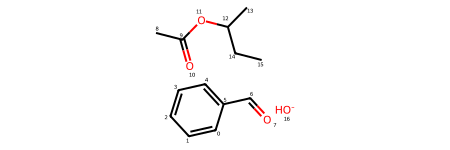

In [68]:
sm

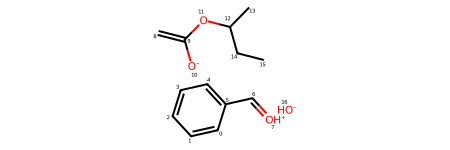

In [69]:
next_mol

In [70]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [71]:
mech

[8, 7, 8, 9, 10]

In [72]:
is_next_step = True
next_step = [0,0,0,0,0]

7 sigma star
13 pi star
14 sigma star


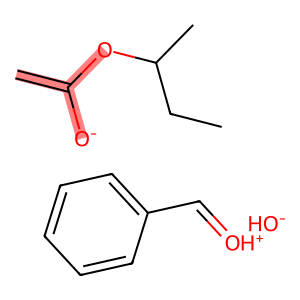

In [73]:
bonds_to_highlight = []
atoms_to_highlight = []
prepare_molecule(next_mol)
if mech[4] is not None:
    pot_source =next_mol.GetAtomWithIdx(mech[4])
    if pot_source.HasProp('source'):
        for a in next_mol.GetAtomWithIdx(mech[4]).GetNeighbors():
            if a.HasProp('sink'):
                print(a.GetIdx(), a.GetSymbol(), a.GetProp('sink'))
                atoms_to_highlight.append(a.GetIdx())
            for b in a.GetBonds():
                if b.HasProp('sink'):
                    bonds_to_highlight.append(b.GetIdx())
                    print(b.GetIdx(), b.GetProp('sink'))
            
if mech[3] is not None:
    pot_sink =next_mol.GetAtomWithIdx(mech[3])
    if pot_sink.HasProp('sink'):
        for a in next_mol.GetAtomWithIdx(mech[3]).GetNeighbors():
            if a.HasProp('source'):
                print(a.GetIdx(), a.GetSymbol(), a.GetProp('source'))
                atoms_to_highlight.append(a.GetIdx())
            for b in a.GetBonds():
                if b.HasProp('source'):
                    bonds_to_highlight.append(b.GetIdx())
                    print(b.GetIdx(), b.GetProp('source'))


for a in next_mol.GetAtoms():
    if a.GetIdx() not in atoms_to_highlight + [mech[3], mech[4]]:
        a.ClearProp('source')
        a.ClearProp('sink')
        if a.GetFormalCharge() == 0:
            a.SetNoImplicit(False)
for b in next_mol.GetBonds():
    if b.GetIdx() not in bonds_to_highlight:
        b.ClearProp('source')
        b.ClearProp('sink')
        b.ClearProp('source_bond_atom')
        b.ClearProp('sink_bond_atom')
        b.ClearProp('source_other_atom')
  


Chem.Draw.MolToImage(next_mol, size=(300, 300), highlightBonds=bonds_to_highlight, highlightAtoms=atoms_to_highlight)

In [74]:
try:
    connected_mols, mechanism, mol_inp = execute_step(next_mol)
except Exception as e:
    print(e)
for i, product in enumerate(connected_mols):
    fp = np.array(make_fingerprint(mol_inp, mechanism[i]))
    pred = clf.predict(fp.reshape(1,-1))[0]
    print(f'Product {i}, predicted: {pred}')


Product 0, predicted: 0
Product 1, predicted: 0
Product 2, predicted: 1
Product 3, predicted: 0
Product 4, predicted: 0


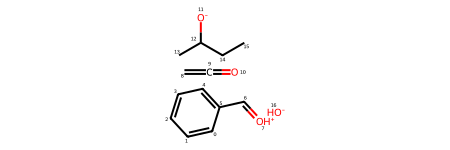

In [80]:
connected_mols[0]

In [53]:
for a in next_mol.GetAtoms():
    if a.HasProp('source'):
        print(a.GetIdx(), a.GetSymbol(), a.GetProp('source'))

0 I lone pair
